# ЛАБОРАТОРНА РОБОТА № 4

## Візуальний аналіз даних та часові ряди — аналіз у двох середовищах

**Курс:** СК26 «Інтелектуальний аналіз та візуалізація даних»
**Кафедра систем штучного інтелекту, Національний університет «Львівська політехніка»**
**Оцінювання:** 4 бали

---

## Визначення варіанта

Заповніть три поля в клітинці нижче й виконайте обидві службові клітинки —
номер варіанта, ринок і товар визначаться автоматично.

In [54]:
# ── Заповніть три поля ──────────────────────────────────────────
SURNAME_NAME = 'Бугай Софія'      # прізвище та ім'я
GROUP        = 'СШІ-34'      # шифр групи, наприклад СШІ-31
NUMBER       = 2       # ваш номер за списком групи (1–30)

assert SURNAME_NAME.strip(), 'Впишіть прізвище та ім\'я'
assert GROUP.strip(),        'Впишіть групу'
assert isinstance(NUMBER, int) and 1 <= NUMBER <= 30, 'Номер має бути цілим від 1 до 30'
print('Дані прийнято:', SURNAME_NAME, '|', GROUP, '| номер', NUMBER)

Дані прийнято: Бугай Софія | СШІ-34 | номер 2


In [55]:
# ── Службова клітинка: визначення варіанта. Змінювати не потрібно ──
import json

VARIANTS = json.load(open('lr4_variants_student.json', encoding='utf-8'))
V = VARIANTS[NUMBER - 1]

MARKET, GOOD, GOOD_UA = V['ринок'], V['товар'], V['товар_укр']

print('=' * 72)
print(f'ВАРІАНТ {V["варіант"]}   ·   {SURNAME_NAME}   ·   {GROUP}')
print('=' * 72)
print()
print(f'   Ринок:  {MARKET}')
print(f'   Товар:  {GOOD_UA}   (у наборі даних: {GOOD})')
print()
print('Далі в роботі користуйтеся змінними MARKET і GOOD —')
print('тоді весь код автоматично працюватиме саме з вашим рядом.')
print()
print('Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців')
print('Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)')

ВАРІАНТ 2   ·   Бугай Софія   ·   СШІ-34

   Ринок:  Chernihiv
   Товар:  гречка   (у наборі даних: Buckwheat grits - Retail)

Далі в роботі користуйтеся змінними MARKET і GOOD —
тоді весь код автоматично працюватиме саме з вашим рядом.

Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців
Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)


> ⚠️ Якщо ці дві клітинки не виконано, усі подальші завдання не мають сенсу:
> перевіряти роботу будуть **за вашим варіантом**, а не за тим рядом, який ви оберете самі.

| | |
|---|---|
| **Дата здачі** | |
| **Підпис** | Софія Бугай |

---
## Мета роботи

Виконати повний цикл аналізу одного часового ряду **у двох середовищах** — у Python та в Orange —
і пояснити, чому однаково названі метрики в них дають різні числа.

## Вихідні дані

| Файл | Зміст |
|---|---|
| `ціни_україна_2014_2017.csv` | Роздрібні ціни на 25 товарів по 28 ринках України, щомісяця, 03.2014 – 12.2017 |
| `lr4_variants_student.json` | Розподіл варіантів (зчитується автоматично) |
| `ЛР4_помилковий_аналіз.ipynb` | Звіт колеги, який треба відрецензувати (завдання 8) |

Це той самий набір, з яким ми працювали на лекції 4. **Національне середнє в завданнях не використовується** —
ваш ряд це конкретний обласний ринок.

## Що здавати

1. **`ЛР4_Прізвище_Варіант.ipynb`** — цей зошит із вашим кодом, графіками та письмовими висновками.
2. **`ряд_для_orange.csv`** — експортований ряд (завдання 9).
3. **`потік_orange.ows`** — збережений потік Orange.
4. **Знімки екрана** з Orange для завдань 10–13 — вставте їх у зошит або додайте окремими файлами.

## Правила

* **Код пишете самостійно** — у цьому зошиті навмисно немає заготовок.
* **Користуватися штучним інтелектом дозволено**, але ви зобов'язані заповнити декларацію в кінці зошита.
* **Кожне число має супроводжуватися висновком словами.** Робота, у якій є графіки й таблиці,
  але немає письмових відповідей на поставлені питання, оцінюється як невиконана.
* Усі обчислення мають бути **відтворюваними**: зошит має виконуватися від початку до кінця
  командою *Restart & Run All* без помилок.

---
# ЧАСТИНА 1. Аналіз засобами Python

*Виконується аудиторно.*

## Завдання 1. Підготовка ряду

Витягніть із набору ряд свого варіанта — скористайтеся змінними `MARKET` і `GOOD`,
які визначилися у службовій клітинці, — і приведіть його до **повної місячної сітки**
з березня 2014 по грудень 2017.

**У звіті наведіть:**
1. скільки місяців у сітці та скільки з них мають вимір;
2. у якому саме місяці пропуск;
3. **чому** цей пропуск виник — і чи він у вашому ряді один.

> 💡 **Підказка.** Пропуск є в усіх без винятку рядах набору. Якщо ви знайшли більше одного — перевірте, чи правильно побудована сітка.

In [56]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

In [57]:
# Завдання 1. Підготовка ряду
ФАЙЛ = "ціни_україна_2014_2017.csv"
dp = pd.read_csv(ФАЙЛ)
my_data = dp[(dp.ринок == MARKET) & (dp.товар == GOOD)].copy()
my_data["дата"] = pd.to_datetime(dict(year=my_data["рік"],
                                      month=my_data["місяць"],
                                      day=1))

s = my_data.set_index("дата")["ціна"].sort_index()

grid = pd.date_range("2014-03-01", "2017-12-01", freq="MS")

s_full = s.reindex(grid)

print("Місяців у сітці: ", len(grid))            
print("Місяців із виміром: ", s_full.notna().sum())   
print("Пропуски: ", s_full[s_full.isna()].index.strftime("%m.%Y").tolist())
display(s_full)

Місяців у сітці:  46
Місяців із виміром:  45
Пропуски:  ['08.2017']


2014-03-01     7.4733
2014-04-01     8.0467
2014-05-01     8.0433
2014-06-01     8.0433
2014-07-01     8.0533
2014-08-01     8.1100
2014-09-01     7.9767
2014-10-01     8.0833
2014-11-01     9.3033
2014-12-01    17.2900
2015-01-01    18.3367
2015-02-01    17.9167
2015-03-01    20.3000
2015-04-01    20.6933
2015-05-01    19.3500
2015-06-01    19.1833
2015-07-01    20.0967
2015-08-01    21.5733
2015-09-01    20.1567
2015-10-01    23.9667
2015-11-01    25.5267
2015-12-01    25.1667
2016-01-01    25.1200
2016-02-01    27.9567
2016-03-01    29.8567
2016-04-01    31.8867
2016-05-01    32.4133
2016-06-01    36.3033
2016-07-01    37.2000
2016-08-01    32.7200
2016-09-01    28.5800
2016-10-01    28.4200
2016-11-01    29.2900
2016-12-01    28.8100
2017-01-01    30.1233
2017-02-01    30.0800
2017-03-01    28.7767
2017-04-01    28.2833
2017-05-01    26.6700
2017-06-01    25.5967
2017-07-01    24.8500
2017-08-01        NaN
2017-09-01    23.0433
2017-10-01    21.2400
2017-11-01    20.0100
2017-12-01

**Висновок до завдання 1:**

Витягнувши потрібні дані із набору та перевевши їх у повну місячну сітку, я отримала в загальному 46 значень, заповненими з яких є тільки 45 -  серед періоду з березня 2014 по грудень 2017 пропущено було місяць (08.2017). Пропуск лише один, виник він, скоріш за все, через відсутність вимірів за даний місяць.

## Завдання 2. Заповнення пропуску

Заповніть пропуск. Порівняйте **щонайменше три** способи: перенесення останнього значення,
лінійну інтерполяцію та ще один на ваш вибір.

**У звіті наведіть:**
1. значення, яке дає кожен спосіб;
2. який спосіб ви обрали і **чому саме його**;
3. за якої умови заповнювати пропуск було б **неприпустимо** — наведіть приклад із цього ж набору даних.

> 💡 **Підказка.** Третій пункт стосується не вашого ряду, а принципу. Згадайте, які області зникають із набору у 2014 році.

Заповнення перенесенням останнього значення: 24.85
Заповнення поліноміальною інтерполяцією (другого порядку) по частинах: 24.17
Заповнення середнім сусідніх значень з врахуванням сезонності: 24.12
Заповнення середнім сусідніх значень: 23.95
Заповнення лінійною регресією: 23.95


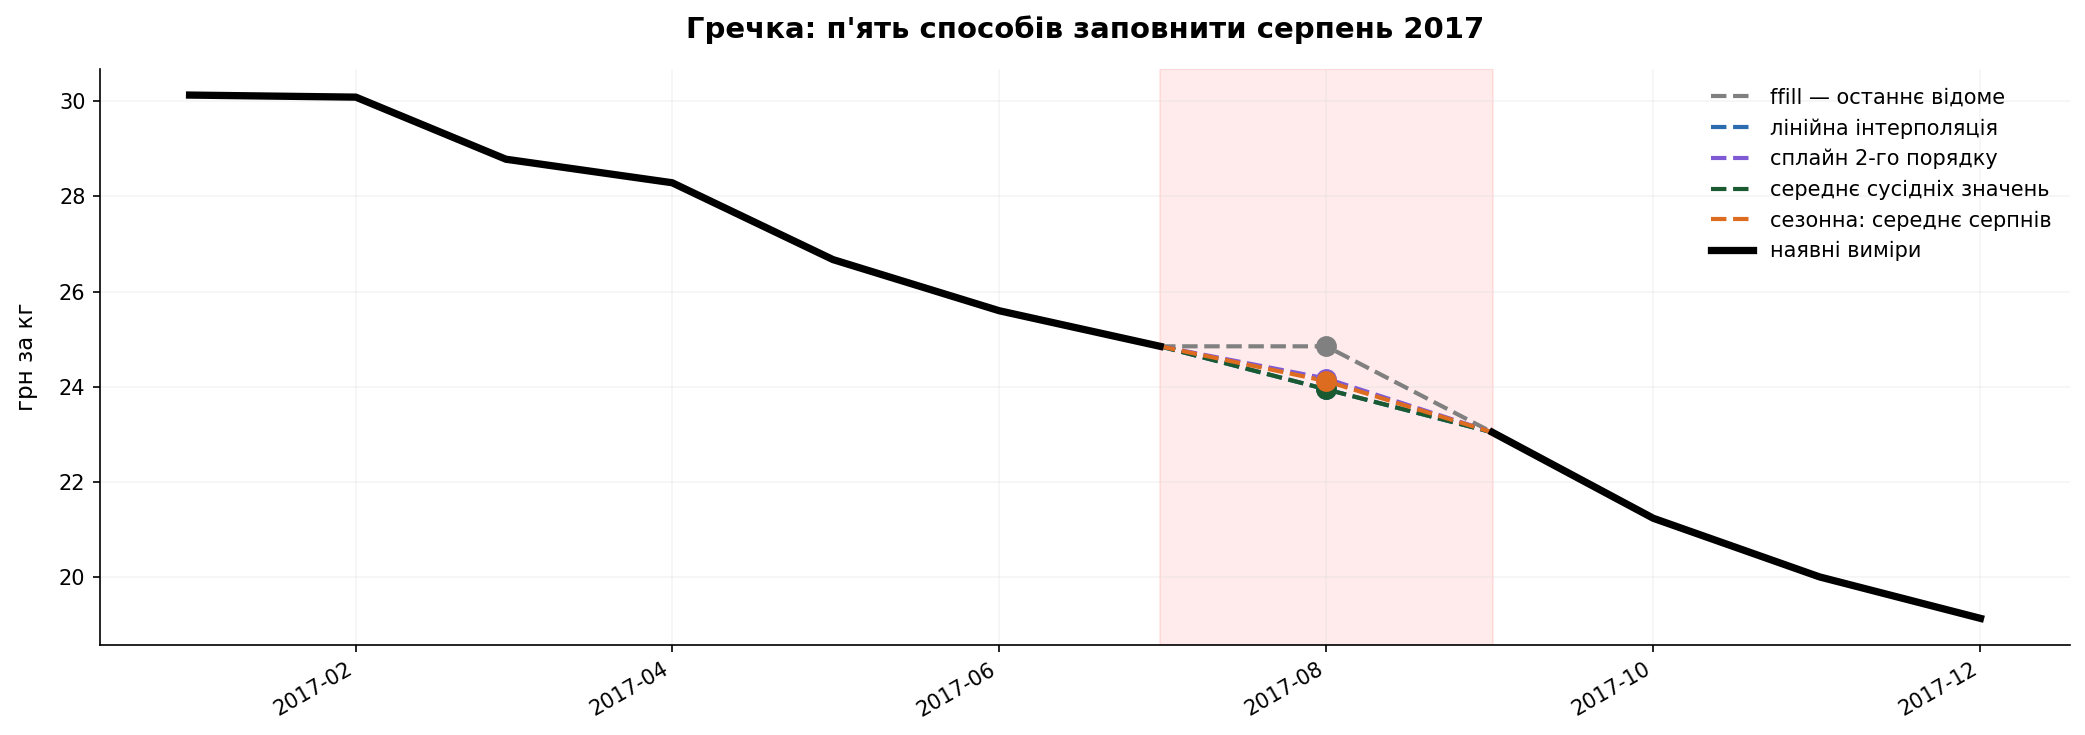

In [58]:
# Завдання 2. Заповнення пропуску
s_ffill  = s_full.ffill()
s_linear = s_full.interpolate("linear")
s_pol  = s_full.interpolate("polynomial", order=2)
s_nmean = s_full.fillna((s_full.shift(1) + s_full.shift(-1)) / 2)

ratio = (s_full["2017-07-01"] / s_full["2016-07-01"] +
         s_full["2017-09-01"] / s_full["2016-09-01"]) / 2
s_seasonal = s_full.copy()
s_seasonal["2017-08-01"] = s_full["2016-08-01"] * ratio

print(f"Заповнення перенесенням останнього значення: {s_ffill["2017-08-01"]:.2f}")
print(f"Заповнення поліноміальною інтерполяцією (другого порядку) по частинах: {s_pol["2017-08-01"]:.2f}")
print(f"Заповнення середнім сусідніх значень з врахуванням сезонності: {s_seasonal["2017-08-01"]:.2f}")
print(f"Заповнення середнім сусідніх значень: {s_nmean["2017-08-01"]:.2f}")
print(f"Заповнення лінійною регресією: {s_linear["2017-08-01"]:.2f}")

s_2017 = s_full.loc["2017-01-01":"2017-12-01"]

jul_val = s_2017["2017-07-01"]
sep_val = s_2017["2017-09-01"]

v_ffill = s_ffill["2017-08-01"]
v_linear = s_linear["2017-08-01"]
v_pol = s_pol["2017-08-01"]
v_nmean = s_nmean["2017-08-01"]
v_seasonal = s_seasonal["2017-08-01"]

methods = {
    'ffill — останнє відоме': (v_ffill, 'grey'),
    'лінійна інтерполяція': (v_linear, '#2b6cb0'),
    'сплайн 2-го порядку': (v_pol, '#805ad5'),
    'середнє сусідніх значень': (v_nmean, "#1a5a31"),
    'сезонна: середнє серпнів': (v_seasonal, '#dd6b20')
}

fig, ax = plt.subplots(figsize=(14, 5), dpi=150)

aug_start = pd.Timestamp("2017-07-01")
aug_end = pd.Timestamp("2017-09-01")
ax.axvspan(aug_start, aug_end, color='red', alpha=0.08, zorder=1)

d_segment = [pd.Timestamp("2017-07-01"), pd.Timestamp("2017-08-01"), pd.Timestamp("2017-09-01")]

for label, (val, color) in methods.items():
    ax.plot(d_segment, [jul_val, val, sep_val], linestyle='--', color=color, linewidth=2, label=label, zorder=2)
    ax.plot(pd.Timestamp("2017-08-01"), val, marker='o', color=color, markersize=9, zorder=3)

s_before = s_2017.loc[:"2017-07-01"]
s_after = s_2017.loc["2017-09-01":]

ax.plot(s_before.index, s_before.values, color='black', linewidth=3.5, label='наявні виміри', zorder=4)
ax.plot(s_after.index, s_after.values, color='black', linewidth=3.5, zorder=4)

ax.set_title("Гречка: п'ять способів заповнити серпень 2017", fontsize=14, fontweight='bold', pad=15)
ax.set_ylabel("грн за кг", fontsize=11, labelpad=10)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(True, linestyle='-', alpha=0.3, color='gainsboro')

ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
fig.autofmt_xdate(rotation=30)

ax.legend(frameon=False, fontsize=10, loc='upper right')

plt.tight_layout()
plt.show()

**Висновок до завдання 2:**

Я спробувала 5 способів заповнення пропуску: 
1. Перенесення значення (зверху) -> 24.85
2. Поліноміальна інтерполяція -> 24.17
3. Середнє сусідніх значень з врахуванням сезонності -> 24.12
4. Середнє сусідніх значень -> 23.95
5. Лінійна регресія -> 23.95

З усіх способів я обрала *третє* - воно враховує періодичність.

## Завдання 3. Візуальна розвідка

Побудуйте **не менше трьох** графіків свого ряду, які відповідають на різні питання.

**У звіті наведіть:**
1. для кожного графіка — яке питання він ставить і **чому обрано саме таку геометрію та шкалу**;
2. одну знахідку, якої ви не очікували до побудови графіків.

> 💡 **Підказка.** Графік без пояснення вибору форми не зараховується. Нагадування з лекції: геометрія — це твердження про дані.

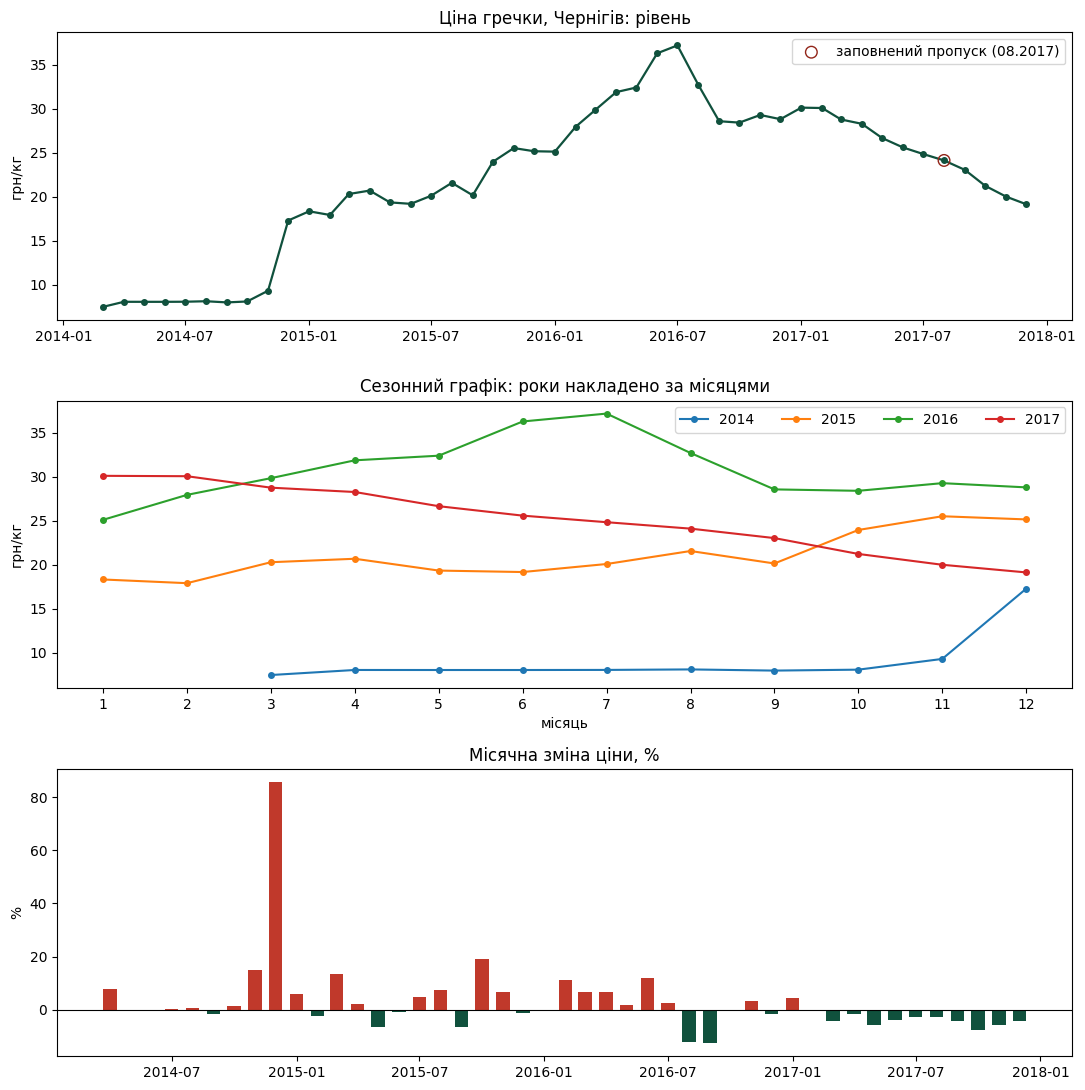

Найбільший місячний стрибок: 12.2014 85.8 %


In [59]:
# Завдання 3. Візуальна розвідка
GAP = pd.Timestamp("2017-08-01")

fig, axes = plt.subplots(3, 1, figsize=(11, 11))

ax = axes[0]
ax.plot(s_seasonal.index, s_seasonal.values, marker="o", ms=4, lw=1.6, color="#10513D")
ax.scatter([GAP], [s_seasonal[GAP]], s=70, facecolors="none", edgecolors="#922519", zorder=5,
           label="заповнений пропуск (08.2017)")
ax.set_title("Ціна гречки, Чернігів: рівень"); ax.set_ylabel("грн/кг"); ax.legend()

ax = axes[1]
tmp = pd.DataFrame({"price": s_seasonal.values, "year": s_seasonal.index.year, "month": s_seasonal.index.month})
for yr, g in tmp.groupby("year"):
    ax.plot(g["month"], g["price"], marker="o", ms=4, label=str(yr))
ax.set_xticks(range(1, 13)); ax.set_xlabel("місяць"); ax.set_ylabel("грн/кг")
ax.set_title("Сезонний графік: роки накладено за місяцями"); ax.legend(ncol=4)

ax = axes[2]
chg = s_seasonal.pct_change().dropna() * 100
ax.bar(chg.index, chg.values, width=20,
       color=np.where(chg.values >= 0, "#C0392B", "#10513D"))
ax.axhline(0, color="k", lw=0.8)
ax.set_title("Місячна зміна ціни, %"); ax.set_ylabel("%")

plt.tight_layout(); plt.show()

print("Найбільший місячний стрибок:", chg.idxmax().strftime("%m.%Y"), round(chg.max(), 1), "%")

**Висновок до завдання 3:**

Я створила 3 графіки: 
1. Ціна гречки за весь час у гривнях --- показує абсолютне значення ціни за місяцями --- зображено лінією з маркерами, бо дані впорядковані в часі, а місяці дискретні.
2. Сезонність --- показує абсолютні значення, порівнюючи їх за місяцями - кожен місяць як окрема лінія показує як ціна змінюється не тільки з часом, але і за сезонами --- те ж саме, що у першому. 
3. Місячна зміна у відсотках --- показує, як змінювалась ціна відносно сама себе за місяцями -- зображено стовпчиками, бо це величини з початком від нуля, а напрямок наявно покакує зниження/збільшення ціни. 

## Завдання 4. Розкладання на складові

Розкладіть ряд на тренд, сезонну складову та залишок методом STL із періодом 12.

**У звіті наведіть:**
1. чотирипанельний графік розкладання;
2. числові значення сили сезонності $F_S$ та сили тренду $F_T$;
3. **висновок: чи є у вашому ряді сезонність**, із посиланням на порогове значення.

> 💡 **Підказка.** STL поверне сезонну складову завжди. Ваше завдання — вирішити, чи вона означає щось, а не чи вона є.

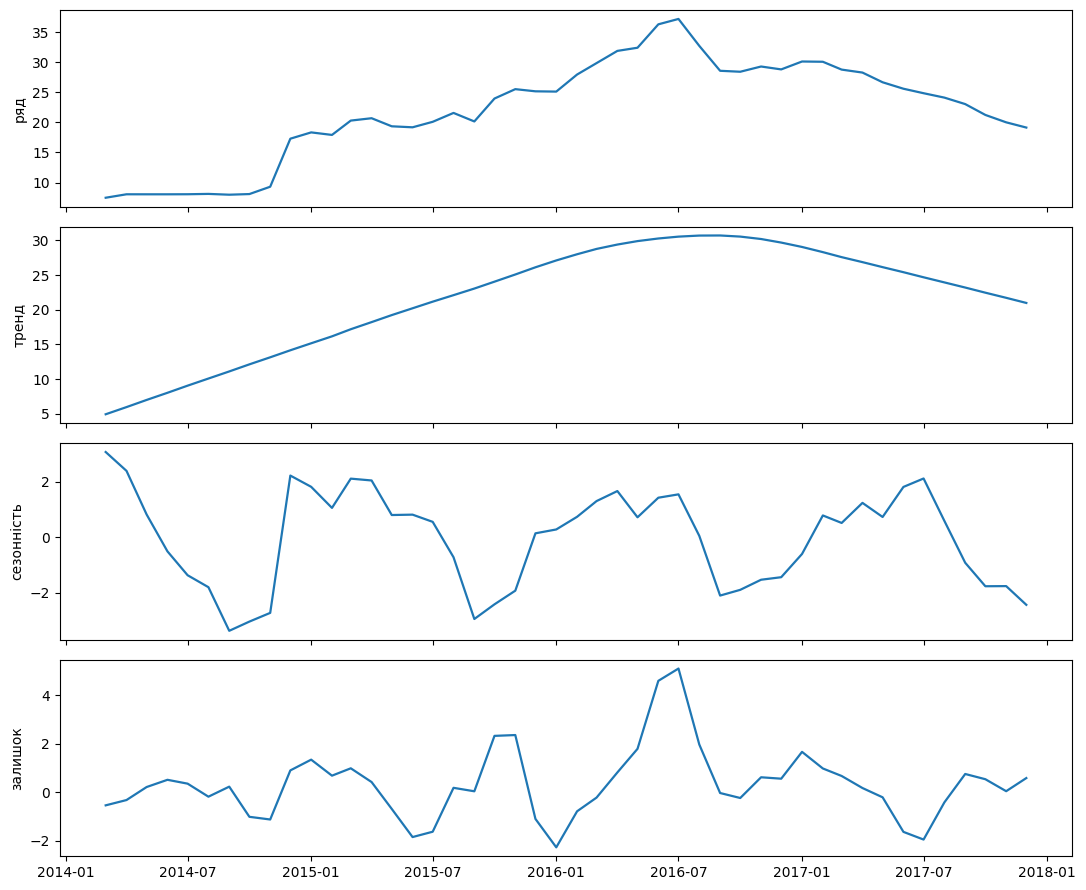

F_S (сила сезонності) = 0.593
F_T (сила тренду)     = 0.969


In [60]:
# Завдання 4. Розкладання на складові
from statsmodels.tsa.seasonal import STL

res = STL(s_seasonal, period=12, robust=False).fit()

fig, axes = plt.subplots(4, 1, figsize=(11, 9), sharex=True)
for ax, d, t in zip(axes,
                    [s_seasonal, res.trend, res.seasonal, res.resid],
                    ["ряд", "тренд", "сезонність", "залишок"]):
    ax.plot(d.index, d.values, lw=1.6); ax.set_ylabel(t)
plt.tight_layout(); plt.show()

var = np.var
Fs = max(0, 1 - var(res.resid) / var(res.seasonal + res.resid))
Ft = max(0, 1 - var(res.resid) / var(res.trend + res.resid))
print(f"F_S (сила сезонності) = {Fs:.3f}")
print(f"F_T (сила тренду)     = {Ft:.3f}")

**Висновок до завдання 4:**

STL показує сильний тренд (F_T = 0,969): зростання цін до осені 2016 року і подальший спад. Сила сезонності F_S = 0,593 трішка більша за середину, тож стійкої сезонності ряд не виявляє, хоча профіль містить осінні мінімуми, узгоджені з циклом урожаю. Частина «сезонного» стрибка наприкінці 2014 року є відлунням одноразового зсуву рівня. Залишок має структуру навколо піку літа 2016 року: модель не повністю описує цей пік.

## Завдання 5. Стаціонарність

Побудуйте ACF і PACF вихідного ряду та його першої різниці. Застосуйте тести ADF і KPSS до обох.

**У звіті наведіть:**
1. графіки ACF і PACF до та після диференціювання;
2. таблицю з $p$-значеннями обох тестів для обох рядів;
3. висновок про стаціонарність **із зазначенням, узгоджуються тести між собою чи ні**;
4. якщо не узгоджуються — ваше пояснення, чому.

> 💡 **Підказка.** Нульові гіпотези ADF і KPSS протилежні. Перш ніж писати висновок, перевірте, що ви не переплутали напрямок.

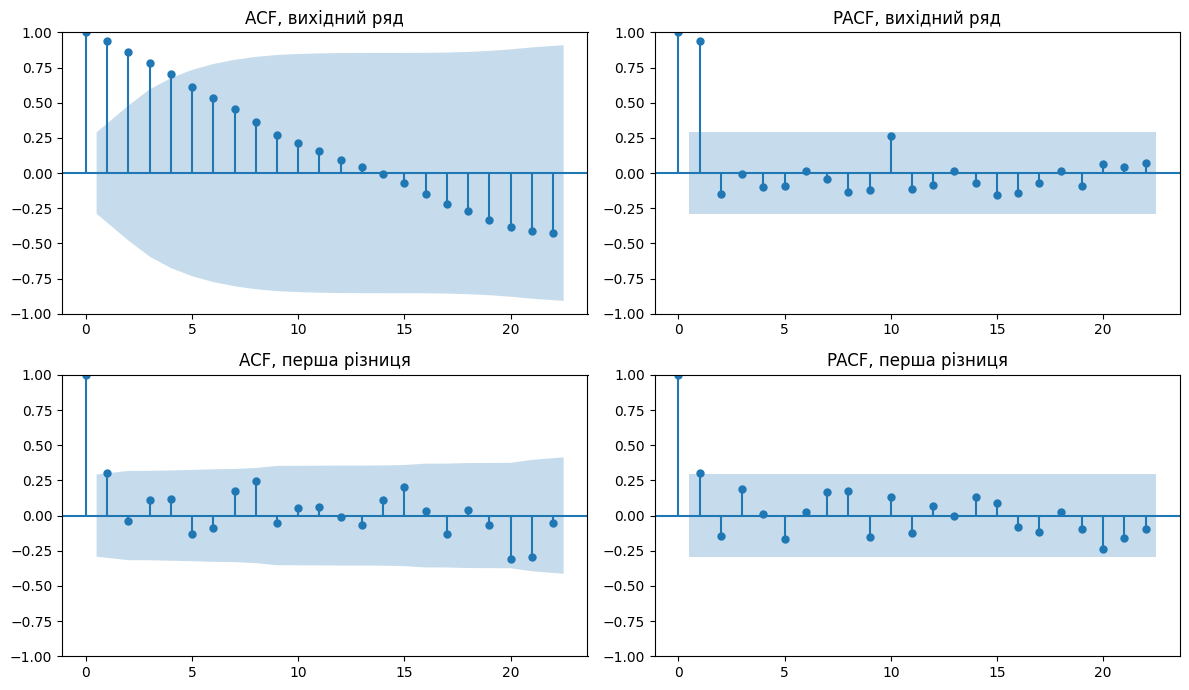

,ADF p (H0: одиничний корінь),KPSS p (H0: стаціонарний)
вихідний ряд,0.4000,0.0171
перша різниця,0.0001,0.0392


In [61]:
# Завдання 5. Стаціонарність
import warnings
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, kpss

d1 = s_seasonal.diff().dropna()

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
plot_acf (s_seasonal, lags=22, ax=axes[0, 0]);               axes[0, 0].set_title("ACF, вихідний ряд")
plot_pacf(s_seasonal, lags=22, ax=axes[0, 1], method="ywm"); axes[0, 1].set_title("PACF, вихідний ряд")
plot_acf (d1,  lags=22, ax=axes[1, 0]);               axes[1, 0].set_title("ACF, перша різниця")
plot_pacf(d1,  lags=22, ax=axes[1, 1], method="ywm"); axes[1, 1].set_title("PACF, перша різниця")
plt.tight_layout(); plt.show()

def tests(x):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        p_adf  = adfuller(x, autolag="AIC")[1]
        p_kpss = kpss(x, regression="c", nlags="auto")[1]
    return p_adf, p_kpss

tab = pd.DataFrame(
    [tests(s_seasonal), tests(d1)],
    index=["вихідний ряд", "перша різниця"],
    columns=["ADF p (H0: одиничний корінь)", "KPSS p (H0: стаціонарний)"]).round(4)
display(tab)

**Висновок до завдання 5:**

Вихідний ряд нестаціонарний: ACF повільно згасає, ADF не відхиляє одиничний корінь (p = 0,40), KPSS відхиляє стаціонарність (p = 0,017), тести збігаються. Перша різниця стаціонарна за ADF (p = 0,0001); KPSS дає погранично значущий результат (p = 0,039), чутливий до вибору лагів і частково пов'язаний із викидом у різниці в грудні 2014 року. ACF і PACF різниці мають лише слабкий лаг 1 (≈ 0,30) на межі значущості, сезонних піків немає.

## Завдання 6. Базисні прогнози та ретроспективна перевірка

Побудуйте **чотири** базисні прогнози: наївний, сезонний наївний, середнє та дрейф.
Оцініть їх **ретроспективною перевіркою з рухомим початком**: **7 фолдів по 3 кроки**,
навчальна частина розширюється.

**У звіті наведіть:**
1. таблицю MAE, RMSE і MAPE для всіх чотирьох базисів;
2. який базис виявився найкращим і **чому саме він** — поясніть через властивості вашого ряду;
3. для порівняння: ту саму оцінку, зроблену звичайним випадковим поділом 75/25, і **у скільки разів** вона відрізняється.

> 💡 **Підказка.** Кількість фолдів і кроків задана жорстко — у Частині 2 вона має збігтися з налаштуваннями Orange.

In [62]:
# Завдання 6. Базисні прогнози та ретроспективна перевірка
def forecast(name, train, h):
    if name == "наївний":
        return np.repeat(train[-1], h)
    if name == "сезонний наївний":
        return np.array([train[len(train) - 12 + (i % 12)] for i in range(h)])
    if name == "середнє":
        return np.repeat(train.mean(), h)
    if name == "дрейф":
        slope = (train[-1] - train[0]) / (len(train) - 1)
        return train[-1] + slope * np.arange(1, h + 1)
    raise ValueError(name)

def metrics(a, f):
    e = a - f
    return dict(MAE=np.mean(np.abs(e)),
                RMSE=np.sqrt(np.mean(e ** 2)),
                **{"MAPE, %": np.mean(np.abs(e / a)) * 100})

def rolling_origin(fn, y, H=3, K=7):
    A, F = [], []
    for k in range(K):
        t0 = len(y) - K * H + k * H
        A += list(y[t0:t0 + H])
        F += list(fn(y[:t0], H))
    return np.array(A), np.array(F)

rows = {}
y = s_seasonal.to_numpy(dtype=float)
n = len(y)
H, K = 3, 7
for nm in ["наївний", "сезонний наївний", "середнє", "дрейф"]:
    A, F = rolling_origin(lambda tr, h, nm=nm: forecast(nm, tr, h), y, H, K)
    rows[nm] = metrics(A, F)
base_tab = pd.DataFrame(rows).T.round(3)
display(base_tab.sort_values("MAE"))

rng = np.random.default_rng(42)
idx = np.arange(n); rng.shuffle(idx)
n_test = int(round(0.25 * n))
test_idx = np.sort(idx[:n_test]); train_idx = np.sort(idx[n_test:])

def random_split_error(kind):
    A, F = [], []
    for i in test_idx:
        prev = train_idx[train_idx < i]
        if kind == "наївний":
            if len(prev) == 0: continue
            F.append(y[prev[-1]])
        else:
            F.append(y[train_idx].mean())
        A.append(y[i])
    return metrics(np.array(A), np.array(F))

rs = pd.DataFrame({k: random_split_error(k) for k in ["наївний", "середнє"]}).T.round(3)
display(rs)
print("MAE наївного: рухомий початок / випадковий поділ =",
      round(base_tab.loc["наївний", "MAE"] / rs.loc["наївний", "MAE"], 2))

,MAE,RMSE,"MAPE, %"
наївний,2.202,2.937,8.152
дрейф,2.677,3.650,10.272
сезонний наївний,8.133,9.268,29.374
середнє,8.173,9.828,26.925


,MAE,RMSE,"MAPE, %"
наївний,1.554,2.198,5.633
середнє,7.486,8.609,45.417


MAE наївного: рухомий початок / випадковий поділ = 1.42


**Висновок до завдання 6:**

На семи фолдах із горизонтом 3 місяці найкращим базисом є наївний (MAE 2,20 грн, RMSE 2,94 грн, MAPE 8,2 %). Дрейф гірший на 21 % за MAE, оскільки екстраполює довгостроковий висхідний нахил в період спаду цін 2016–2017 рр. Сезонний наївний і середнє помиляються приблизно в 3,7 раза сильніше, що узгоджується зі слабкою сезонністю та зсувом рівня ряду.

## Завдання 7. Модель ARIMA

Побудуйте модель ARIMA і оцініть її **на тих самих 7 фолдах по 3 кроки**.

Обов'язково використайте порядок **(1, 1, 1)** — саме його ви відтворюватимете в Orange.
Додатково визначте, який порядок $(p, d, q)$ ви обрали б **за виглядом ACF і PACF** із завдання 5.

**У звіті наведіть:**
1. MAE, RMSE і MAPE моделі ARIMA(1,1,1) на рухомому початку;
2. обґрунтування порядку, який ви обрали б самостійно, з посиланням на конкретні лаги;
3. **порівняння з найкращим базисом із завдання 6** — і прямий висновок, чи має ця модель право на існування;
4. графік залишків моделі та висновок, чи лишилася в них структура.

> 💡 **Підказка.** Якщо ARIMA програла базису — це законний результат, а не помилка. Напишіть про це прямо.

,MAE,RMSE,"MAPE, %"
наївний,2.202,2.937,8.152
"ARIMA(1,1,1)",2.404,3.402,8.773
дрейф,2.677,3.650,10.272
сезонний наївний,8.133,9.268,29.374
середнє,8.173,9.828,26.925


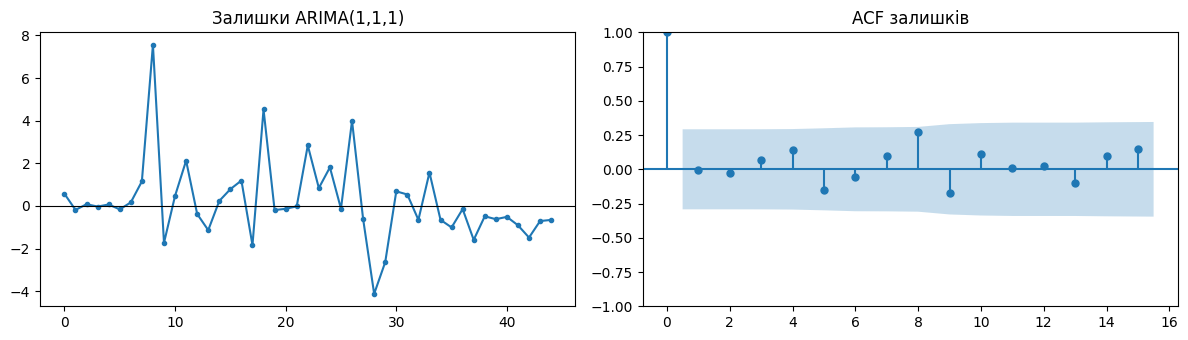

,lb_stat,lb_pvalue
10,10.087072,0.432888


In [63]:
# Завдання 7. Модель ARIMA
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox

def arima_fc(train, h, order=(1, 1, 1)):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        return ARIMA(train, order=order).fit().forecast(h)

A, F = rolling_origin(lambda tr, h: arima_fc(tr, h), y, H, K)
arima_m = metrics(A, F)
cmp = pd.concat([base_tab, pd.DataFrame({"ARIMA(1,1,1)": arima_m}).T.round(3)])
display(cmp.sort_values("MAE"))

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    fit = ARIMA(y, order=(1, 1, 1)).fit()
r = np.asarray(fit.resid)[1:]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].plot(r, marker="o", ms=3); axes[0].axhline(0, color="k", lw=0.8); axes[0].set_title("Залишки ARIMA(1,1,1)")
plot_acf(r, lags=15, ax=axes[1]); axes[1].set_title("ACF залишків")
plt.tight_layout(); plt.show()
display(acorr_ljungbox(r, lags=[10], return_df=True))

**Висновок до завдання 7:**

ARIMA(1,1,1) на семи фолдах із горизонтом 3 місяці дала MAE 2,404, RMSE 3,402 і MAPE 8,77 %, що гірше за наївний прогноз (2,202 / 2,937 / 8,15 %), але краще за дрейф, сезонний наївний і середнє. Це узгоджується з тим, що перша різниця ряду близька до білого шуму. Залишки моделі не мають значущої автокореляції (Льюнг–Бокс, лаг 10: p = 0,43; з поправкою на кількість параметрів p ≈ 0,26), але містять викид у грудні 2014 року (+7,5), мають нерівномірну дисперсію й систематично від'ємні значення в 2017 році. Отже, складніша модель не дала виграшу порівняно з наївним прогнозом.

## Завдання 8. Точка зміни режиму

Знайдіть у своєму ряді точку, після якої змінюється **рівень** ряду.
Скористайтеся скануванням: для кожної кандидатної дати порівняйте середні до і після
та оберіть дату з найбільшою t-статистикою.

**У звіті наведіть:**
1. графік ряду з позначеною знайденою датою;
2. дату, значення t-статистики, середні рівні до і після;
3. **чи є ця точка значущою** — і якщо ні, так і напишіть;
4. чим знайдена точка відрізняється від звичайного сезонного сплеску у вашому ряді.

> 💡 **Підказка.** Не плутайте зсув рівня з сезонним піком. Якщо «аномалії» повторюються щороку в ті самі місяці — це сезон.

дата=12.2014  t=-19.59  p=1.45e-21  середнє до=8.13  після=25.41


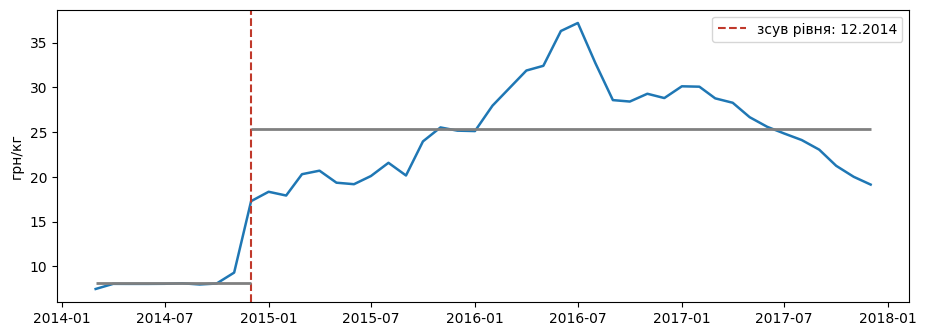

кандидатних дат: 35 | p з поправкою Бонферроні: 5.066725351486644e-20
2014-12-01    7.99
2015-12-01   -0.36
2016-12-01   -0.48
2017-12-01   -0.87
Name: ціна, dtype: float64


In [64]:
# Завдання 8. Точка зміни режиму
from scipy import stats
MIN_SEG = 6
res_scan = []
for i in range(MIN_SEG, n - MIN_SEG + 1):
    a, b = y[:i], y[i:]
    t = stats.ttest_ind(a, b, equal_var=False)
    res_scan.append((s_seasonal.index[i], t.statistic, t.pvalue, a.mean(), b.mean()))
scan = pd.DataFrame(res_scan, columns=["дата", "t", "p", "середнє до", "середнє після"])
best = scan.loc[scan["t"].abs().idxmax()]
print(f"дата={best['дата']:%m.%Y}  t={best['t']:.2f}  p={best['p']:.2e}  середнє до={best['середнє до']:.2f}  після={best['середнє після']:.2f}")

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(s_seasonal.index, s_seasonal.values, lw=1.8)
ax.axvline(best["дата"], color="#C0392B", ls="--", label=f"зсув рівня: {best['дата']:%m.%Y}")
ax.hlines(best["середнє до"],   s_seasonal.index[0],     best["дата"], color="gray", lw=2)
ax.hlines(best["середнє після"], best["дата"], s_seasonal.index[-1],    color="gray", lw=2)
ax.legend(); ax.set_ylabel("грн/кг"); plt.show()

m = len(scan)
print("кандидатних дат:", m, "| p з поправкою Бонферроні:", min(1, best["p"] * m))

d = s_seasonal.diff()
print(d[d.index.month == best["дата"].month].round(2))

**Висновок до завдання 8:**

Новий рівень починається з грудня 2014. Середнє зростає з 8,13 до 25,41 грн (у 3,1 раза), t = −19,59. На графіку видно причину: майже плоский ряд близько 8 грн дев'ять місяців, потім стрибок на +7,99 грн за один місяць (+86 %). Попередній місяць (листопад) уже додав близько +1,2 грн, тож підйом, схоже, почався на місяць раніше, а t-сканування обрало грудень як точку найбільшого розриву середніх. Відмінність від сезонного сплеску: у наступні грудні зміни дорівнюють −0,36, −0,48 і −0,87 грн. Сезонний сплеск мав би повторюватися щороку в тому самому місяці, тут цього немає, тож це одноразовий зсув рівня.

## Завдання 9. Рецензія на чужий аналіз

Відкрийте `ЛР4_помилковий_аналіз.ipynb`. Це звіт, зроблений на іншому ряді з того самого набору.
Він виконується без помилок і виглядає переконливо, але містить **методологічні помилки**.

**У звіті наведіть:**
1. перелік знайдених помилок — для кожної вкажіть номер клітинки, суть помилки й **чим вона небезпечна**;
2. для трьох найсерйозніших — як саме їх виправити.

> 💡 **Підказка.** Помилок щонайменше вісім. Шукайте не синтаксис, а порушення принципів роботи з часовими рядами.

In [65]:
# Завдання 9. Рецензія на чужий аналіз
print("Завдання 1:")
s_full = s.reindex(grid)
print(len(s_full), s_full.isna().sum(),
      s_full[s_full.isna()].index.strftime('%m.%Y').tolist())
s_fill = s_full.interpolate("linear") 

print("\nЗавдання 6")
adf_p  = adfuller(s_fill, autolag="AIC")[1]
kpss_p = kpss(s_fill, regression="c", nlags="auto")[1]
d1 = s_fill.diff().dropna()

print("\nЗавдання 8:")
y_9 = s_fill.to_numpy(float)
A,  F  = rolling_origin(lambda tr, h: arima_fc(tr, h, (1, 1, 1)), y_9, 3, 7)
An, Fn = rolling_origin(lambda tr, h: forecast("наївний", tr, h), y_9, 3, 7)
print("ARIMA :", metrics(A,  F))
print("Наївний:", metrics(An, Fn)) 

Завдання 1:
46 1 ['08.2017']

Завдання 6

Завдання 8:


C:\Users\Sofiya\AppData\Local\Temp\ipykernel_1840\1817828506.py:9: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_p  = adfuller(s_fill, autolag="AIC")[1]
C:\Users\Sofiya\AppData\Local\Temp\ipykernel_1840\1817828506.py:10: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  kpss_p = kpss(s_fill, regression="c", nlags="auto")[1]


ARIMA : {'MAE': np.float64(2.4246040179434982), 'RMSE': np.float64(3.414727198594671), 'MAPE, %': np.float64(8.86835918448193)}
Наївний: {'MAE': np.float64(2.210630952380952), 'RMSE': np.float64(2.9416002297300055), 'MAPE, %': np.float64(8.188829737038352)}


**Висновок до завдання 9:**

**Завдання 1:**
Аналіх пропусків зроблено тільки з наданих даних, без врахування часової компоненти (якщо пропущений місяць, він не показуватиметься як NaN у списку, його просто не буде).

**Завдання 2:**
Масштаб подорожчання оцінено за двома точками (перша й остання), і ці ціни номінальні. Кінець ряду лежить у фазі падіння (останні 12 місяців: 27,4 → 17,7 грн), пік у 5,2 раза вищий за початок. Висновок про «зниження купівельної спроможності» взято з номінальних цін без інфляції, курсу й доходів.

**Завдання 3:**
Прогнозованість двох товарів порівняно за MAE у гривнях. Рівні цін різні (≈ 21 грн проти ≈ 78 грн). Висновок перевернутий: яловичина прогнозується втричі точніше у відносному вимірі. Метрики різного масштабу не порівнюють.

**Завдання 4:**
Спільний тренд дає високу кореляцію майже завжди, а кореляція не доводить причинності. Спільні фактори (курс, національний шок 2014 року) діють на обидві області. На різницях кореляція ≈ 0,94, тож зв'язок реальний, але він може значною мірою бути зумовлений спільним стрибком.

**Завдання 5:**
STL завжди повертає якусь сезонну криву, сили сезонності (F_S) не пораховано. Тут же ряд має пропуск, лише ~3,8 циклу, і стрибок 2014 року просочується в сезонність.

**Завдання 6:**
ADF: p > 0,05 означає нестаціонарність (H0 це одиничний корінь), а зроблено висновок «ряд стаціонарний, диференціювання не потрібне». Також немає KPSS для перехресної перевірки. Одразу друга різниця «для надійності» (різницю першого порядку не перевірено). Виведену ACF не інтерпретовано: лаг 1 змінюється з +0,43 (перша різниця) на −0,13 (друга)	Надмірне диференціювання вносить штучну від'ємну кореляцію й збільшує дисперсію. p-value ADF на другій різниці нічого не доводить, воно мале майже завжди.

**Завдання 7:**
Метод відрізняє «далеко від середнього», а не «незвично для свого часу». Середнє й σ використовують майбутнє. Висновок «нетипові події, які потребують розслідування» ні на чому не ґрунтується. Потрібне тренд-залишкове чи ковзне медіанне порогування (наприклад, за залишком STL).

**Завдання 8:**
Витік майбутнього в навчання і спотворена часова структура. Часові ряди ділять лише за хронологією. Немає базису в тих самих умовах. «Сезонний наївний» MAE пораховано на всьому ряді (in-sample, інша вибірка) і ніде не порівняно. Висновок «висока точність» зроблено за одним числом у гривнях, без MAPE і без перевірки залишків. Жодна модель не оцінюється без порівняння з простим прогнозом. Тут не доведено, що ARIMA хоч щось дає. Також суперечність із висновком у завданні 5 - використано ARIMA, хоча автори визначити ряд як стаціонарний.

**Завдання 9:**
Фінальна модель ARIMA(2,2,1) не така, як оцінена у розділі 8 (1,1,1), і суперечить власному висновку «диференціювання не потрібне». Прогноз на 12 місяців без інтервалів, а «ціна продовжить зростати» суперечить останнім 12 місяцям падіння	Оцінено одну модель, а прогноз зроблено іншою, жодним чином не перевіреною. При d = 2 прогноз екстраполює зміну приросту, і довгий горизонт швидко розходиться.

**Завдання 10:**
Заголовок «динаміка за 2016 рік» приховує спад другої половини. Тут саме твердження про зріст правильне, але зображення перебільшує його й показує вибіркове вікно, скоротивши всі стовпці майже на значення першого, витягнувши їх усі в порівнянні.


## Завдання 10. Експорт ряду для Orange

Збережіть підготовлений ряд у файл `ряд_для_orange.csv` **рівно у такому вигляді**:

| Стовпець | Тип | Зміст |
|---|---|---|
| `date` | текст у форматі `РРРР-ММ-ДД` | перше число місяця |
| `price` | число | ціна, пропуск уже заповнений |

Один рядок на місяць, 46 рядків плюс заголовок, роздільник — кома, кодування UTF-8.

**У звіті наведіть:**
1. підтвердження, що файл має 46 рядків даних і не містить порожніх значень.

> 💡 **Підказка.** Формат заданий жорстко: Orange має отримати **точно ті самі** дані, що й Python, інакше порівняння в Частині 2 втрачає сенс.

In [66]:
# Завдання 10. Експорт ряду для Orange
out = pd.DataFrame({"Date": s_seasonal.index.strftime("%Y-%m-%d"), "Price": s_seasonal.values})
out.to_csv("ряд_для_orange.csv", index=False, encoding="utf-8")

chk = pd.read_csv("ряд_для_orange.csv")
print("рядків даних:", len(chk), "| порожніх значень:", int(chk.isna().sum().sum()))
print(chk.dtypes.to_dict())
assert len(chk) == 46 and chk.isna().sum().sum() == 0
assert chk["Date"].str.fullmatch(r"\d{4}-\d{2}-01").all()
chk.head()

рядків даних: 46 | порожніх значень: 0
{'Date': <StringDtype(na_value=nan)>, 'Price': dtype('float64')}


,Date,Price
0,2014-03-01,7.4733
1,2014-04-01,8.0467
2,2014-05-01,8.0433
3,2014-06-01,8.0433
4,2014-07-01,8.0533


**Висновок до завдання 10:**

Файл виведено та перевірено на кількість пропусків і розміру.

---
# ЧАСТИНА 2. Той самий аналіз засобами Orange

*Виконується самостійно.*

Потрібен додаток **Timeseries**: у Orange відкрийте *Options → Add-ons…* і встановіть `Orange3-Timeseries`.

**Головна умова цієї частини:** Orange має отримати **ті самі дані** й **ті самі налаштування перевірки**,
що й Python у Частині 1. Тоді будь-яка розбіжність у числах пояснюється **лише означеннями метрик**,
а не різними даними чи різними моделями. Саме це вам і треба довести.

## Завдання 11. Потік опрацювання даних

Побудуйте в Orange потік:

`File` → `As Timeseries` → `Interpolate` → `Line Chart`

У віджеті **File** завантажте свій `ряд_для_orange.csv`; переконайтеся, що `date` розпізнано
як **time**, а `price` — як **numeric**. У віджеті **As Timeseries** оберіть `date` як часову змінну.

**У звіті наведіть:**
1. знімок екрана з побудованим потоком;
2. знімок `Line Chart` із вашим рядом;
3. підтвердження, що графік у Orange збігається з графіком із завдання 3.

> 💡 **Підказка.** Якщо `date` розпізнано як текст, поверніться до завдання 10 і перевірте формат дати.

In [67]:
# Завдання 11. Потік опрацювання даних

**Висновок до завдання 11:**

Графік зроблений самостійно:

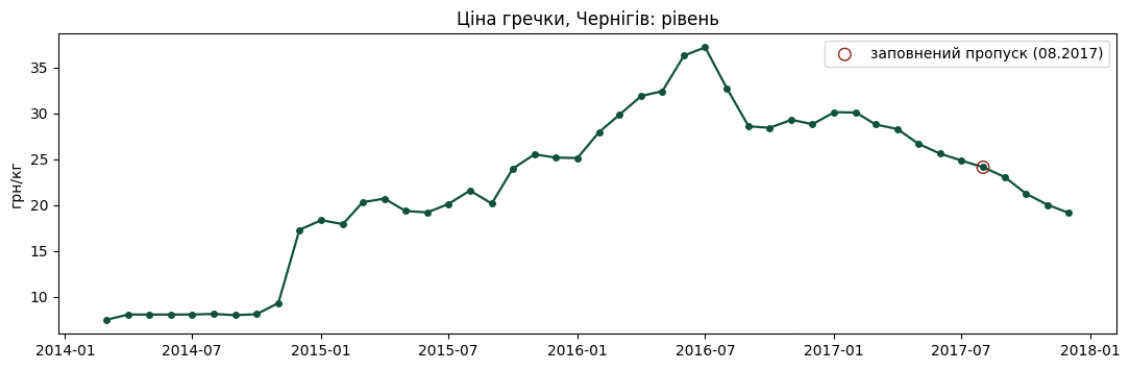


Графік з Orange:

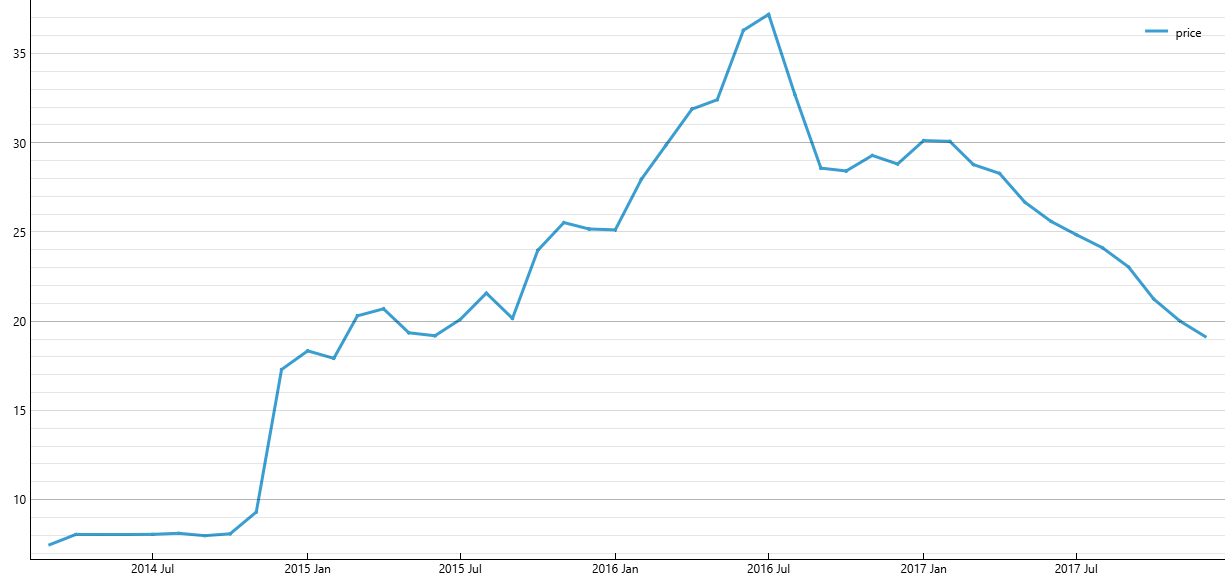

Як видно з графіків, результати збігаються

## Завдання 12. Автокореляція та диференціювання

Додайте до потоку віджети `Correlogram`, `Difference` та `Seasonal Adjustment`.

**У звіті наведіть:**
1. знімок корелограми;
2. зіставлення з ACF із завдання 5: **чи збігаються висновки** про значущі лаги;
3. знімок сезонно скоригованого ряду та порівняння з сезонною складовою STL із завдання 4.

> 💡 **Підказка.** Orange і statsmodels рахують автокореляцію однаково — якщо картина різна, перевірте, чи однакові дані на вході.

In [68]:
# Завдання 12. Автокореляція та диференціювання

**Висновок до завдання 12:**

**Корелограма:**

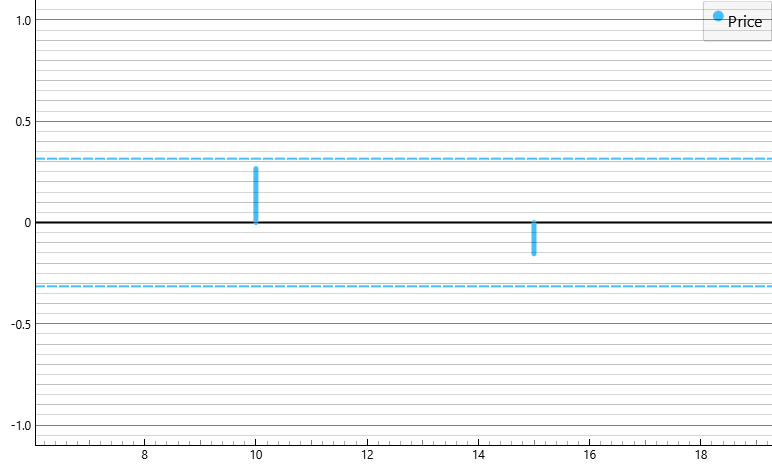

На жаль, Orange показав лише лаги 10 і 15 зі значеннями ≈ 0,3 та -0.15, що збігається з обчисленнями у Python.



**Різниця:**

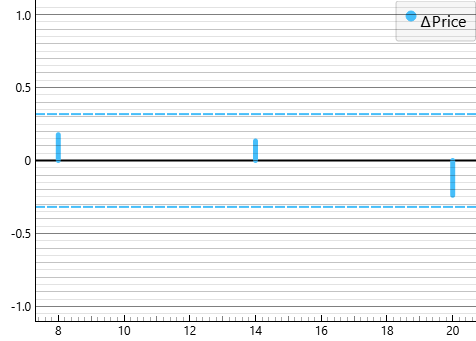

Тут схожа проблема із корелограмою - надано тільки три значення, однак вони збігаються із обчисленнями у завданні 5



**Сезонне налаштування:**

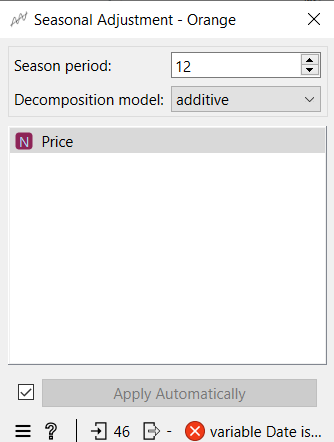

Orange видає помилку, яку я не змогла виправити, тому виписала еквівалентний код у пайтоні:

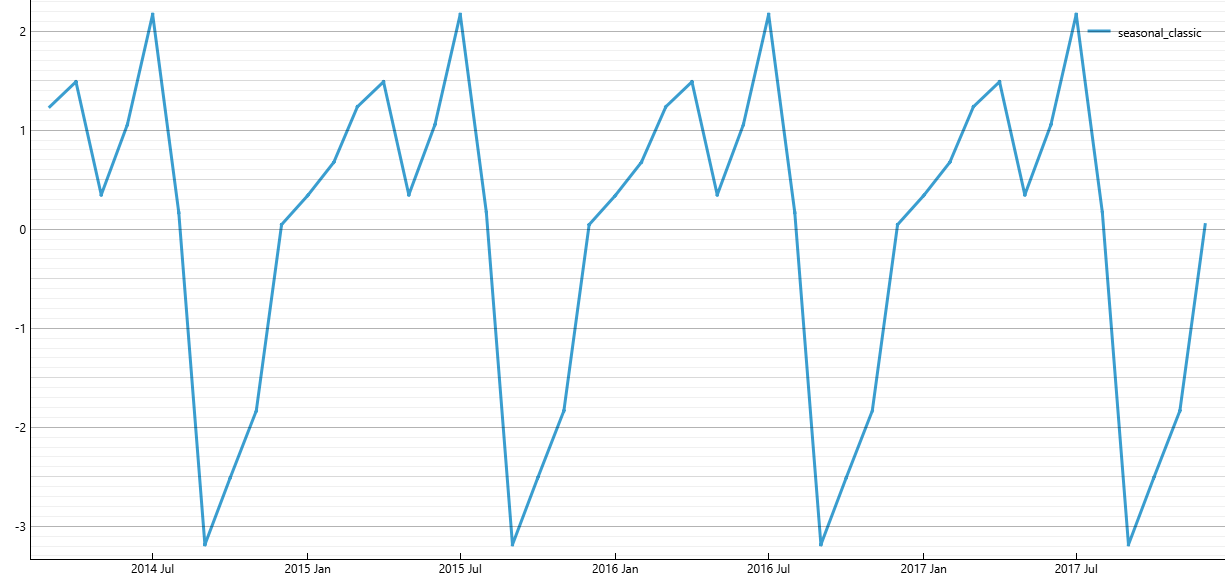

Класичне розкладання для кожного місяця дає однаковий профіль у всі роки, а STL дозволяє профілю повільно змінюватись. Тому в STL сезонна складова виглядає менш регулярною, особливо наприкінці 2014 року (відлуння стрибка). Спільне в обох: осінній мінімум (вересень–листопад).

## Завдання 13. Модель і оцінювання

Додайте `ARIMA Model` з порядком **(1, 1, 1)** та `Model Evaluation`.

У віджеті **Model Evaluation** встановіть **Number of folds = 7** та **Forecast steps = 3**.

**У звіті наведіть:**
1. знімок таблиці Model Evaluation з усіма метриками;
2. **що станеться, якщо лишити типові налаштування** (20 фолдів × 3 кроки) — наведіть повідомлення, яке видасть Orange, і поясніть, звідки воно береться;
3. які саме 7 фолдів перевіряє Orange — тобто на яких відрізках ряду навчається модель.

> 💡 **Підказка.** Orange відмовиться працювати при типових налаштуваннях. Це не збій, а наслідок довжини вашого ряду — порахуйте, якої саме.

In [69]:
# Завдання 13. Модель і оцінювання

**Висновок до завдання 13:**

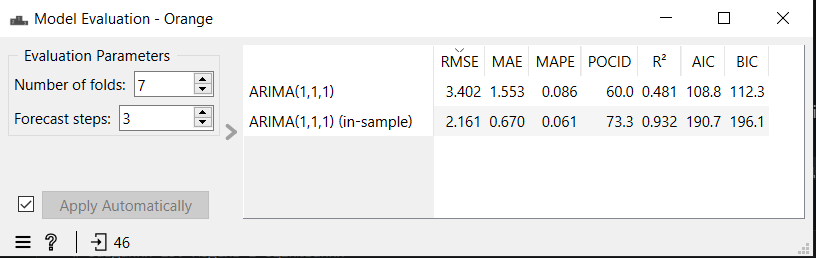

Із 20-ма фолдами:

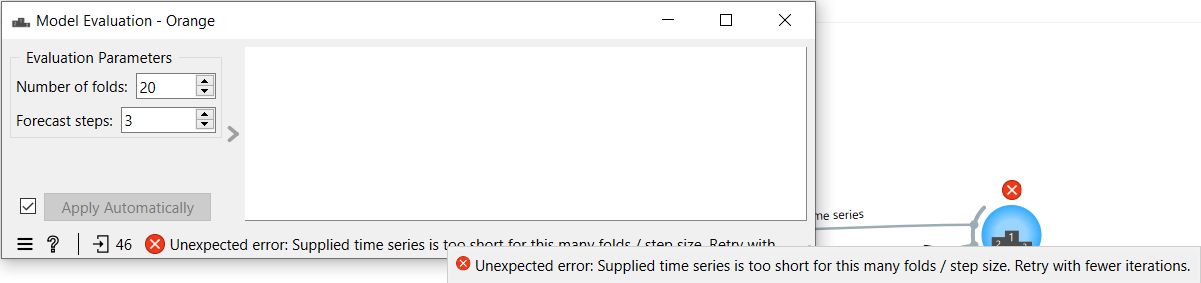

20 фолдів × 3 кроки = 60 тестових точок, а в ряді лише 46. Навчальної частини не лишається взагалі (46 − 60 < 0), звідси повідомлення «time series is too short for this many folds / step size. Retry with fewer iterations».

З 7 фолдами: 46 − 7·3 = 25 точок для навчання у першому фолді, 28 у другому і так до 43 в останньому

## Завдання 14. Чому числа не збігаються

Порівняйте метрики Orange з метриками, які ви отримали в Частині 1 для **тієї самої** моделі
ARIMA(1,1,1) на **тих самих** 7 фолдах.

Для кожної з чотирьох метрик Orange — `RMSE`, `MAE`, `MAPE`, `POCID` — **відтворіть її значення в Python**,
тобто напишіть формулу, за якою Orange отримав саме це число, і переконайтеся, що ваш розрахунок
збігається з таблицею Orange до третього знака.

**У звіті наведіть:**
1. таблицю на чотири рядки: метрика · значення Orange · ваше відтворення в Python · формула;
2. **яка з метрик не відповідає своїй назві** — і чим саме вона відрізняється від того, що зазвичай позначають цією абревіатурою;
3. яка метрика збіглася між середовищами одразу і чому;
4. висновок: що саме треба перевіряти, перш ніж порівнювати числа з двох різних інструментів.

> 💡 **Підказка.** Жодна з розбіжностей не є помилкою Orange. Усі формули відкриті — шукайте їх у вихідному коді додатка Timeseries, файл `functions.py`.

In [70]:
# Завдання 14. Чому числа не збігаються
A, F = rolling_origin(lambda tr, h: arima_fc(tr, h), y, 3, 7)
e = A - F
dA, dF = np.diff(A), np.diff(F)
mine = {
    "RMSE":                  np.sqrt(np.mean(e ** 2)),
    "MAE: середнє |e|":      np.mean(np.abs(e)),
    "MAE: медіана |e|":      np.median(np.abs(e)),
    "MAPE: середнє |e|/A":   np.mean(np.abs(e / A)),
    "MAPE: Σ|e| / ΣA":       np.abs(e).sum() / A.sum(),
    "POCID (dA*dF>0)":       100 * np.mean(dA * dF > 0),
    "POCID (sign==sign)":    100 * np.mean(np.sign(dA) == np.sign(dF)),
}
print(pd.Series(mine).round(4))

orange = {"RMSE": 3.402, "MAE": 1.553, "MAPE": 0.086, "POCID": 60.0}

RMSE                    3.4020
MAE: середнє |e|        2.4045
MAE: медіана |e|        1.5534
MAPE: середнє |e|/A     0.0877
MAPE: Σ|e| / ΣA         0.0859
POCID (dA*dF>0)        65.0000
POCID (sign==sign)     65.0000
dtype: float64


**Висновок до завдання 14:**

MAE - метрика, яка не відповідає назві: за назвою це mean absolute error, середнє |e| (2,40), а Orange показує 1,553, що є медіаною абсолютних помилок. Різниця суттєва: медіана майже не реагує на великі промахи (наприклад, на 2–3 фолди з помилками 5 грн), тому вона помітно менша за середнє.

RMSE: значення 3,402 однакове в обох середовищах. Формула √(середнє e²) єдина й однозначна: немає варіантів, чим усереднювати чи на що ділити, тож збіг лише підтверджує, що прогнози й тестові точки в Orange і Python ті самі.

Різниця в POCID складається з рівно одного переходу: 65,0 це 13 з 20, 60,0 це 12 з 20. Є й закономірність, яка підказує причину. RMSE, MAE і MAPE залежать лише від набору помилок, а не від їхнього порядку. POCID залежить від того, які точки вважаються сусідніми (різниця між послідовними елементами), тож розбіжність спричиняє саме порядок або правило, за яким Orange складає ряди перед обчисленням напрямку.

## Завдання 15. Матриця напрямку зміни

Метрика `POCID` у Orange вимірює, чи правильно модель передбачає **напрямок** зміни ціни.
Розгорніть її в таблицю 2×2: рядки — що сталося насправді (зросла / впала),
стовпці — що передбачила модель.

**У звіті наведіть:**
1. заповнену матрицю 2×2 для вашої моделі;
2. перевірку, що частка правильних передбачень збігається зі значенням POCID із Orange;
3. висновок: чи корисна ваша модель для рішення «купувати зараз чи чекати», і чому це **інше питання**, ніж те, на яке відповідають MAE та RMSE.

> 💡 **Підказка.** Ця матриця — часоворядовий відповідник матриці похибок із класифікації.

In [71]:
# Завдання 15. Матриця напрямку зміни
A, F = rolling_origin(lambda tr, h: arima_fc(tr, h, (1, 1, 1)), y, 3, 7)
H = 3

dA = np.diff(A)

prev_F = F[:-1].copy()
first_step = (np.arange(1, len(F)) % H == 0)
prev_F[first_step] = A[:-1][first_step]
dF = F[1:] - prev_F

actual = np.where(dA > 0, "зросла", "впала")
pred   = np.where(dF > 0, "зросла", "впала")

cm = pd.crosstab(pd.Series(actual, name="факт"), pd.Series(pred, name="прогноз"))
cm = cm.reindex(index=["зросла", "впала"], columns=["зросла", "впала"], fill_value=0)
display(cm)

correct, total = int((actual == pred).sum()), len(dA)
print(f"правильних напрямків: {correct} з {total} = {100*correct/total:.1f} %  (Orange POCID = 60.0)")
assert abs(100 * correct / total - 60.0) < 0.05

прогноз,зросла,впала
факт,,
зросла,3,2
впала,6,9


правильних напрямків: 12 з 20 = 60.0 %  (Orange POCID = 60.0)


**Висновок до завдання 15:**

Модель для цього рішення фактично не корисна. Із 20 тестових місяців вона дала б 8 хибних рішень (6 разів «купуй зараз» перед падінням і 2 рази «чекай» перед зростанням), і її напрямок у цьому періоді не кращий за рівень випадку й за тривіальне правило.

MAE та RMSE вимірюють, наскільки далеко (у гривнях) прогноз від факту, тобто розмір помилки рівня. POCID перевіряє лише знак зміни й не бачить розміру.
Модель може мати велику помилку рівня й правильний напрямок (і навпаки): місячні зміни ціни зазвичай 1–2 грн, помилка RMSE 3,4 грн, тож напрямок прогнозу визначається малою поправкою AR/MA і легко «перевертається».
Для рішення цінні обидва виміри: хибний напрямок при зміні 0,04 грн нічого не коштує, а при зміні на 4,5 грн коштує дорого.

---
# Загальний висновок

Напишіть 8–12 речень, які відповідають на такі питання:

1. Чи є у вашому ряді сезонність і чим ви це довели?
2. Який метод прогнозування виявився найкращим і чи перевершив він найпростіший базис?
3. Чи знайшли ви точку зміни режиму; якщо так — чи є для неї зовнішнє пояснення?
4. Чому однаково названі метрики у двох середовищах дали різні числа?
5. Чого ви не змогли встановити через те, що ряд має лише 46 спостережень?

Мої відповіді:

1. Сезонність сама по собі існує, однак неймовірно слабка (F_S = 0.593)
2. Найефективнішим вийшов наївний метод прогнозування (MAE 2,20 грн, RMSE 2,94, MAPE 8,2 %), і ARIMA(1,1,1) його не перевершила (MAE 2,40, RMSE 3,40, MAPE 8,8 %). Це закономірно, бо перша різниця ряду майже білий шум зі слабкою автокореляцією на лазі 1 (≈ 0,30), тож крім останнього значення передбачувати майже нічого, а напрямок зміни модель вгадала лише у 60 % випадків проти 75 % для правила «завжди впаде».
3. Точку зміни режиму знайдено: грудень 2014 року, коли середня ціна зросла з 8,13 до 25,41 грн (t ≈ −19,6), і формально вона значуща навіть після поправки Бонферроні, хоча p-значення завищене через автокореляцію ряду.
4. Однаково названі метрики дали різні числа через різні формули. Після вирівнювання даних RMSE збігся одразу (3,402), «MAE» Orange виявився медіаною абсолютних помилок (1,553 замість середнього 2,40), а «MAPE» відношенням Σ|e| до ΣA (0,086 замість середнього відношень 0,088). POCID теж відрізнявся (60 проти 65) через інше правило порівняння напрямку на початку кожного фолда.
5. Через лише 46 спостережень я не змогла надійно відрізнити сезонність від зсуву рівня, бо кожен календарний місяць має 3–4 значення, а в ряді лише один злам. Також оцінки ARIMA на навчальних частинах із 25–43 точок нестабільні, 20 фолдів по 3 кроки зробити неможливо (60 > 46), а частка правильних напрямків на 20 переходах статистично не відрізняється від підкидання монети (p ≈ 0,25).

---
# Критерії оцінювання

| Бали | Умова |
|---|---|
| **0** | Ряд не розкладено або прогноз не побудовано. Робота не зарахована. |
| **2** | Виконано лише Частину 1: ряд розкладено й прогноз побудовано, але в Orange аналіз не відтворено. |
| **3** | Виконано обидві частини, проте прогноз не зіставлено з наївним базисом, а розбіжність результатів двох середовищ не пояснено. |
| **4** | Ряд розкладено на складові; прогноз зіставлено з наївним базисом за ретроспективною перевіркою з рухомим початком; той самий аналіз відтворено в Orange; зіставлено результати двох середовищ і пояснено розбіжність метрик. |

**Знімаються бали за:**

* графіки без пояснення вибору геометрії та шкали;
* числа без письмового висновку;
* прогноз без порівняння з базисом;
* висновок «метрики різні, бо середовища різні» без відтворення формул;
* зошит, який не виконується від початку до кінця.

---
# Декларація про використання штучного інтелекту

Використання інструментів штучного інтелекту під час виконання цієї роботи **дозволено**.
Умова одна: ви маєте розуміти кожен рядок зданого коду й кожне написане твердження
і бути готовим пояснити їх на захисті.

Заповніть таблицю. Якщо ШІ не використовувався, напишіть «не використовувався» в першому рядку
й залиште решту порожньою.

| Питання | Ваша відповідь |
|---|---|
| Які інструменти використано (назва, версія) | Claude, Gemini |
| Для яких саме завдань | 2, 3, 4, 5, 6, 7, 8 |
| Що саме було згенеровано (код / текст / пояснення / виправлення помилок) | код |
| Що ви змінили у згенерованому результаті й чому | використала потрібні назви, змінила кількість лагів для графіків |
| Що з отриманого ви **перевірили самостійно** і яким способом | Перевірила усе переглядом та детальним розумінням кожної використаної функції |
| Чи траплялися у відповідях ШІ помилки; якщо так — які | |

**Підтверджую, що розумію весь зданий код і всі зроблені висновки
та можу пояснити будь-яку їх частину на захисті роботи.**

Підпис: Софія Бугай  Дата: 29.10.2026